The main class in this notebook is EmbeddingsGenerator. To get the embeddings of a sentence, make a call to `embeddingsGenerator.get_embeddings(method, list_of_sentences)`

An example is shown in the Playground section below.

## Install Required Libraries

In [0]:
%%capture
# Install the latest Tensorflow version.
!pip3 install --upgrade tensorflow-gpu
# Install TF-Hub.
!pip3 install tensorflow==2.0
!pip3 install tensorflow-hub
!pip3 install bert-for-tf2


## Import Required Libraries to Python

In [0]:
import tensorflow_hub as hub
import tensorflow as tf 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import bert
FullTokenizer = bert.bert_tokenization.FullTokenizer
from tensorflow.keras.models import Model
from sklearn.preprocessing import scale,minmax_scale


## Load Pretrained Models

In [0]:
elmo = hub.load("https://tfhub.dev/google/elmo/3")
print('Done Loading Elmo')

use = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")
print('Done Loading Universal Sentence Encoder')

word2vec = hub.load("https://tfhub.dev/google/Wiki-words-500/2")
print('Done Loading Word2Vec')

nnlm = hub.load("https://tfhub.dev/google/nnlm-en-dim128/2")
print('Done Loading NNLM')

bert_layer = hub.KerasLayer("https://tfhub.dev/tensorflow/bert_en_uncased_L-12_H-768_A-12/1", trainable=True)
print('Done Loading BERT')

albert_layer = hub.KerasLayer("https://tfhub.dev/tensorflow/albert_en_xxlarge/1", trainable=True)
print('Done Loading Albert')

Instructions for updating:
If using Keras pass *_constraint arguments to layers.


Instructions for updating:
If using Keras pass *_constraint arguments to layers.


Done Loading Elmo
Done Loading Universal Sentence Encoder
Done Loading Word2Vec
Done Loading NNLM
Done Loading BERT
Done Loading Albert


## Helper Classes: BERT Model


In [0]:
""" 
Adapted and Modifided From https://colab.research.google.com/drive/1hMLd5-r82FrnFnBub-B-fVW78Px4KPX1#scrollTo=gmR3jHYE_y3X
A wrapper class around the main functionality of BERT
The primary method is get_embeddings
"""

class BertModel:
  '''
  Set Up Requried Objects For BERT
  '''
  def __init__(self, bert_layer):
    self.max_seq_length = 128
    input_word_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                          name="input_word_ids")
    input_mask = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                      name="input_mask")
    segment_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                        name="segment_ids")
    
    pooled_output, sequence_output = bert_layer([input_word_ids, input_mask, segment_ids])
    self.model = Model(inputs=[input_word_ids, input_mask, segment_ids], outputs=[pooled_output, sequence_output])

    vocab_file = bert_layer.resolved_object.vocab_file.asset_path.numpy()
    do_lower_case = bert_layer.resolved_object.do_lower_case.numpy()
    self.tokenizer = FullTokenizer(vocab_file, do_lower_case)

  '''
  Takes a list of sentences and returns their embeddings
  '''
  def get_embeddings(self, sentences):
    return np.array([self.__embed_single_sentence(sentence) for sentence in sentences]).reshape(len(sentences),-1)


  def __embed_single_sentence(self, sentence):
    stokens = self.tokenizer.tokenize(sentence)
    stokens = ["[CLS]"] + stokens + ["[SEP]"]

    input_ids = self.__get_ids(stokens)
    input_masks = self.__get_masks(stokens)
    input_segments = self.__get_segments(stokens)

    pool_embs, all_embs = self.model.predict([[input_ids],[input_masks],[input_segments]])

    return pool_embs

  def __get_masks(self, tokens):
    """Mask for padding"""
    if len(tokens)> self.max_seq_length:
        raise IndexError("Token length more than max seq length!")
    return [1]*len(tokens) + [0] * (self.max_seq_length - len(tokens))


  def __get_segments(self, tokens):
      """Segments: 0 for the first sequence, 1 for the second"""
      if len(tokens)> self.max_seq_length:
          raise IndexError("Token length more than max seq length!")
      segments = []
      current_segment_id = 0
      for token in tokens:
          segments.append(current_segment_id)
          if token == "[SEP]":
              current_segment_id = 1
      return segments + [0] * (self.max_seq_length - len(tokens))


  def __get_ids(self, tokens):
      """Token ids from Tokenizer vocab"""
      token_ids = self.tokenizer.convert_tokens_to_ids(tokens)
      input_ids = token_ids + [0] * (self.max_seq_length-len(token_ids))
      return input_ids

## Helper Classes: Albert Model

In [0]:
"""
A wrapper class around Albert
"""
class AlBertModel(BertModel):
  def __init__(self, albert_layer, bert_layer):
    self.max_seq_length = 128
    input_word_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                          name="input_word_ids")
    input_mask = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                      name="input_mask")
    segment_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                        name="segment_ids")
    pooled_output, sequence_output = bert_layer([input_word_ids, input_mask, segment_ids])
    
    self.model = Model(inputs=[input_word_ids, input_mask, segment_ids], outputs=[pooled_output, sequence_output])

    vocab_file = bert_layer.resolved_object.vocab_file.asset_path.numpy()
    do_lower_case = bert_layer.resolved_object.do_lower_case.numpy()
    self.tokenizer = FullTokenizer(vocab_file, do_lower_case)

## Helper Classes: Embeddings Generator

In [0]:
class EmbeddingsGenerator:
  def __init__(self, elmo, use, word2vec, nnlm, bert, albert):
    self.elmo = elmo
    self.use = use
    self.word2vec = word2vec
    self.nnlm = nnlm 
    self.bert = bert
    self.albert = albert

    self.function_for_model = {
        'elmo': self.get_elmo_embedding,
        'use': self.get_universal_sentence_endocder_embeddings,
        'bert': self.get_bert_embeddings,
        'word2vec': self.get_word2vec_embeddings,
        'nnlm': self.get_nnlm_embeddings,
        'albert': self.get_albert_embeddings
    }

  def get_embeddings(self, method, input):
    return self.function_for_model[method](input)

  def get_elmo_embedding(self, input):
    embeddings = self.elmo.signatures['default'](
        tf.constant(input))["default"]
    return embeddings

  def get_universal_sentence_endocder_embeddings(self, input):
    embeddings = self.use(input)
    return embeddings    

  def get_word2vec_embeddings(self, input):
    embeddings = self.word2vec(input)
    return embeddings

  def get_nnlm_embeddings(self, input):
    embeddings = self.nnlm(input)
    return embeddings

  def get_bert_embeddings(self, input):
    embeddings = self.bert.get_embeddings(input)
    return embeddings

  def get_albert_embeddings(self, input):
    embeddings = self.albert.get_embeddings(input)
    return embeddings

  def print_all(self, sentences):
    for model in self.function_for_model.keys():
      function = self.function_for_model[model]
      if model == 'elmo':
        print('elmo')
        print(function(sentences).shape)
        
      elif model == 'use':
        print('use')
        print(function(sentences).shape)

      elif model == 'word2vec':
        print('word2vec')
        print(function(sentences).shape) 

      elif model == 'nnlm':
        print('nnlm')
        print(function(sentences).shape)   

      elif model == 'bert':
        print('bert')
        print(function(sentences).shape)

      elif model == 'albert':
        print('albert')
        print(function(sentences).shape)

## Playground

In [0]:
## Create Instance of Embeddings Generator
embeddingsGenerator = EmbeddingsGenerator(elmo, use, word2vec, nnlm,  BertModel(bert_layer), AlBertModel(albert_layer, bert_layer))

In [0]:
def plot_similarity(labels, features, rotation):
  corr = np.inner(features, features)
  corr = minmax_scale(corr, feature_range=(0,1))
  sns.set(font_scale=1.2)
  g = sns.heatmap(
      corr,
      xticklabels=labels,
      yticklabels=labels,
      vmin=np.min(corr),
      vmax=np.max(corr),
      cmap="YlOrRd")
  
  g.set_xticklabels(labels, rotation=rotation)
  g.set_title("Text Similarity")

def run_and_plot(messages_, method):
  message_embeddings_ =   embeddingsGenerator.get_embeddings(method, messages_)
  plot_similarity(messages_, message_embeddings_, 90)

In [0]:
# objectives = [
#             "I want to enhance my social skills",
#             "My next goal is having more social skills",
#             "I want to focus on my technical skills",
#             "My technical skills is needed to be enhanced",
#             "My goal for the next year is to have soft skills",
#             "soft skills is my main goal next year",
#             "I want to learn programming languages like java",
#              "I want to learn microsoft c# to make small programs"
# ]

objectives = [
              "A group of kids is playing in a yard and an old man is standing in the background",
              "A group of boys in a yard is playing and a man is standing in the background",
              "Two dogs are fighting",
              "Two dogs are wrestling and hugging",
              " person on a black motorbike is doing tricks with a jacket",
              "A person is riding the bicycle on one wheel",
              "Two groups of people are playing football",
              "Two teams are competing in a football match"
]

### Visualizing Elmo

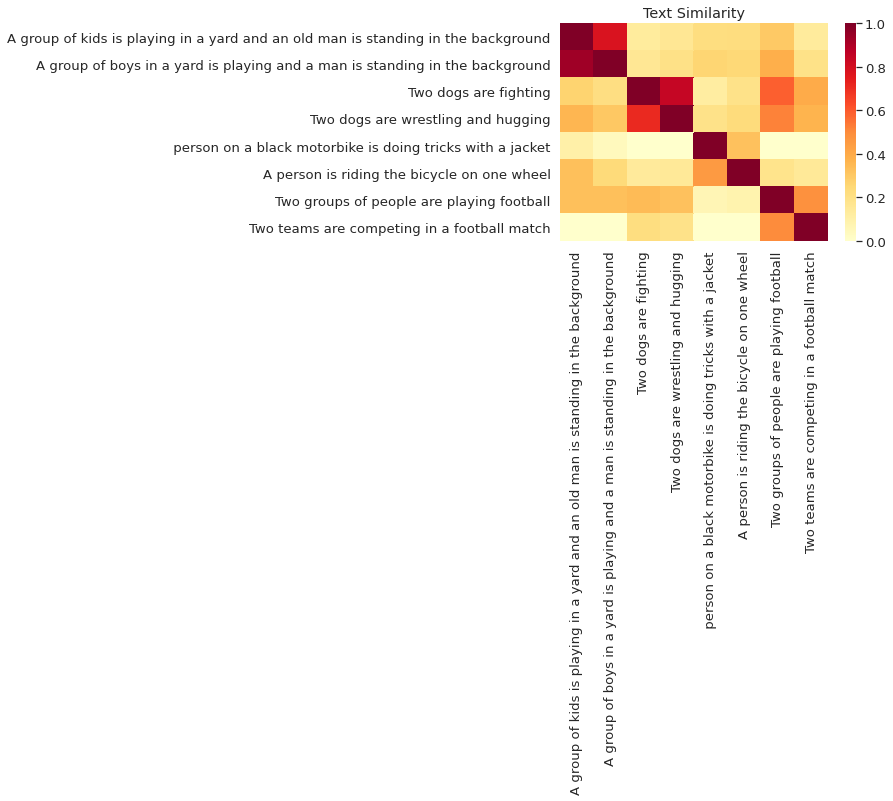

In [0]:
run_and_plot(objectives, 'elmo')


### Visualizing Universal Sentence Encoder

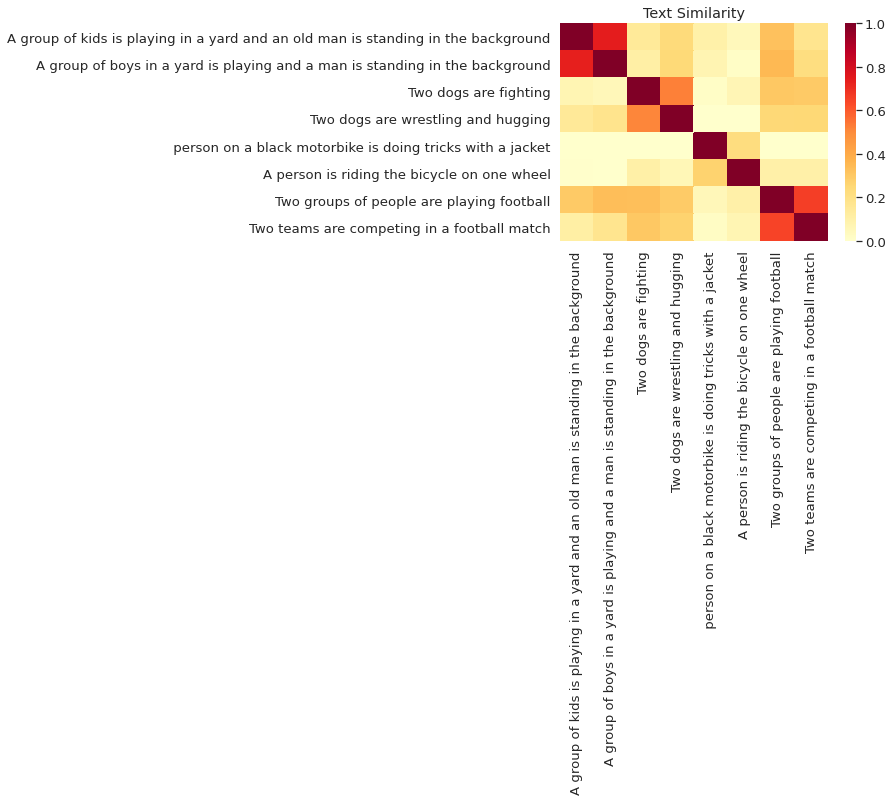

In [0]:
run_and_plot(objectives, 'use')


### Visualizing Wor2Vec

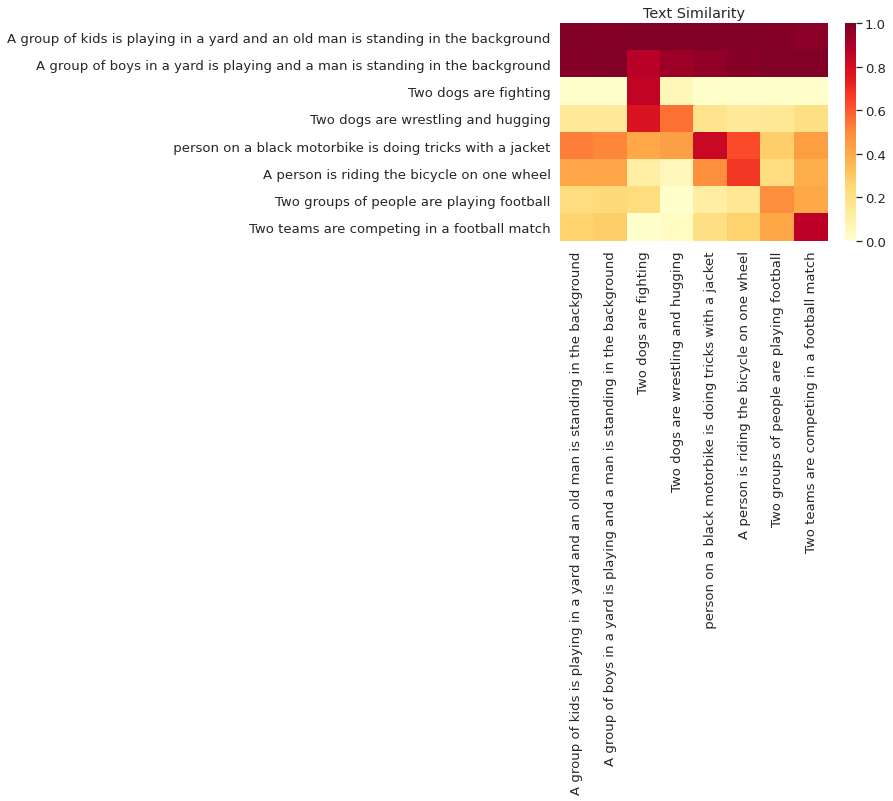

In [0]:
run_and_plot(objectives, 'word2vec')


### Visualizing NNLM

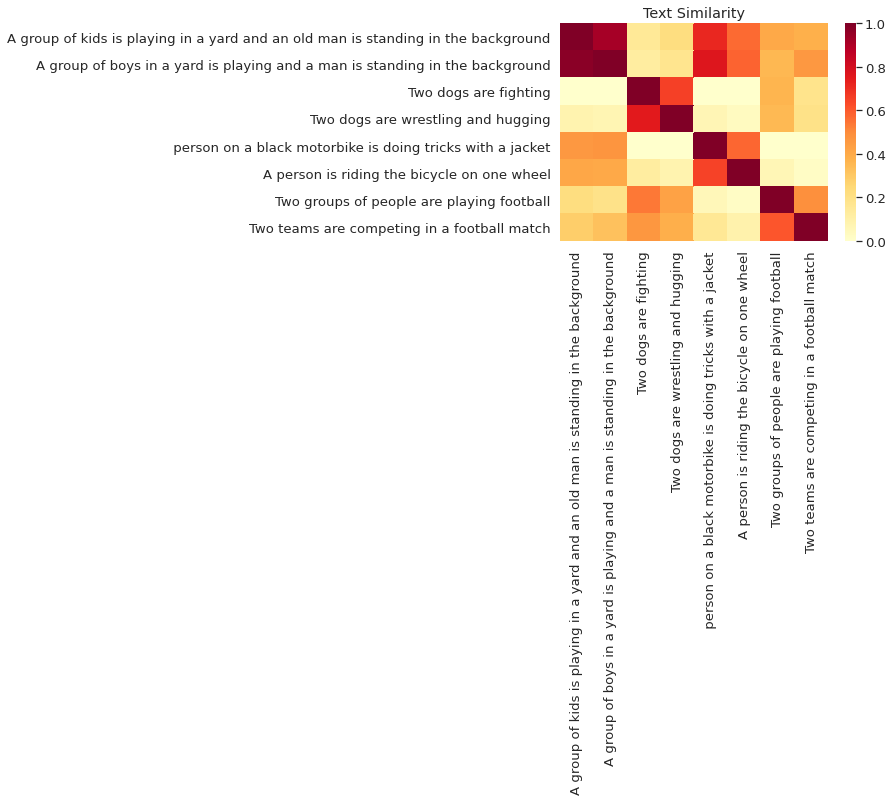

In [0]:
run_and_plot(objectives, 'nnlm')


### Visualizing BERT

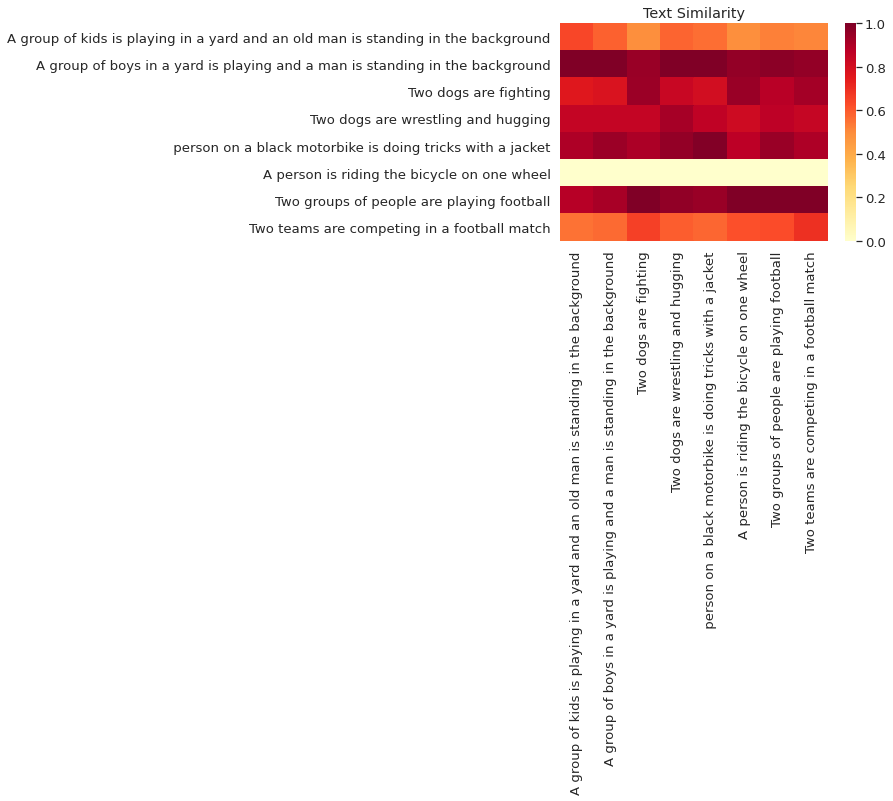

In [0]:
run_and_plot(objectives, 'bert')


### Visualizing Albert

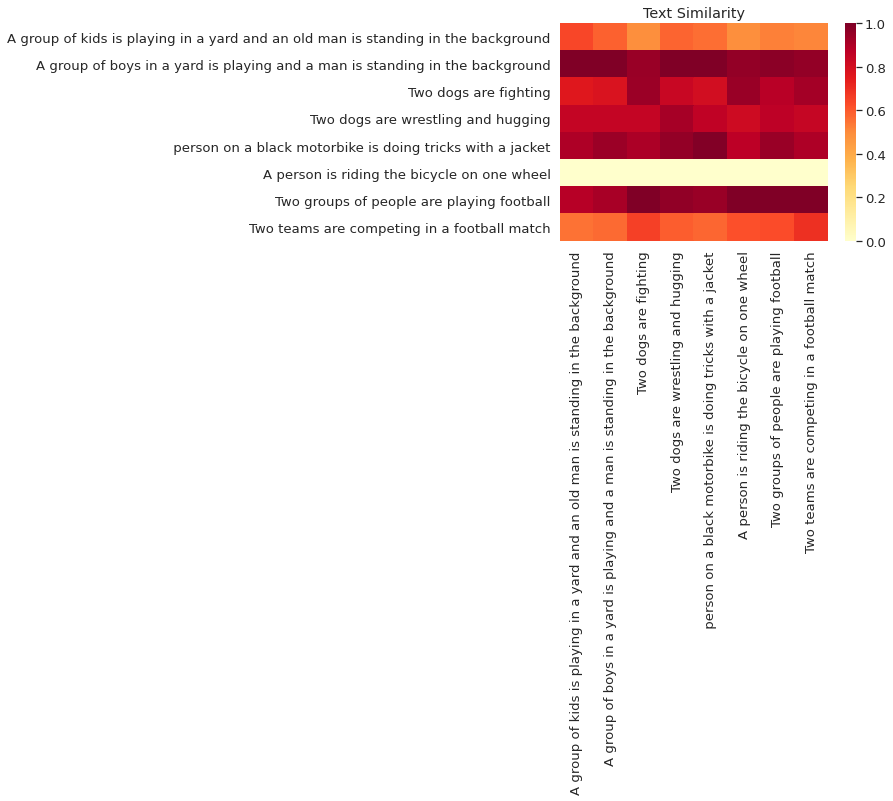

In [0]:
run_and_plot(objectives, 'albert')